# Proyecto Programación y Paradigmas para Ciencia de Datos.


**Alumno:** Torres Jimenez Edgar Iván


## Conjunto de datos elegido: 
### IBM HR Analytics Employee Attrition & Performance

La traducción al español del nombre del Dataset sería: "IBM Recursos Humanos Rendimiento y deserción de los empleados".
Link de descarga: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

In [1]:
enlace = 'https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset'

## Descripción del dataset

En el dataset contamos con 35 columnas, y más de 1400 datos de distintos empleados, las caracteristicas que definen a cada empleado son relacionadas a lo laboral, económico y familiar.

La finalidad es poder predecir si un empleado va a dejar su puesto de trabajo o permanecerá en la compañia.

## CRISP-DM, a modo de recordatorio durante el proyecto:

1. Entendimiento del negocio
2. Entendimiento de los datos (puede retornarnos al primer paso)
3. preparación de los datos
4. Modelado (puede regresarnos al paso anterior)
5. Evaluación (dependiendo el resultado, si falla es probable que tengamos que regresar hasta el primer paso)
6. Puesta en operación [deployment]
7. 

## CRISP-DM: Etapa 1:
### ¿Por qué es importante saber si un empleado renunciará ó no?

Podemos decir que para una compañía los empleados son parte fundamental de sus "recursos", el caso de IBM que es una empresa reconocida en el mundo de la técnología y es muy reconocida por cualquiera que se dedique se quiera dedicar a ésta área, entonces si decimos que los empleados son parte fundamental de una compañía, queremos que los empleados se desarrollen de la mejor manera en el desarrollo de sus actividades, ya que de ello depende su rendimeinto, y ese rendimiento se traduce en ganancias para la empresa.

Cuando tenemos a mucha gente renunciando o siendo despedida, tenemos un problema de alta rotación del personal, al ser IBM una empresa de tamaño transnacional, requiere que esos puestos de trabajo no se queden vacíos, si no no podría cumplir sus objetivos como empresa.

Algunos de los inconvenientes de la alta rotación del personal son:

1. Cuesta mucho dinero y tiempo el proceso de selección, contratación y capacitación de nuevos empleados.
2. Los trabajadores que ya contaban con experiencia, ya no están en la empresa, entones tenemos una especie de "fuga de experiencia".
3. Perdidas en la productividad
4. Perdidas en las ganancias.


Ya teniendo un contexto de los datos que vamos a analizar, su importancia y porqué es importante buscar un modelo para el problema, vamos a hacer un análisis a los datos.

### Importación de bibliotecas

- NumPy permitirá realizar operaciones matemáticas.

- Pandas permitirá cargar y manipular el dataset.

- Matplotlib y Seaborn se utilizarán para el análisis exploratorio.

- RANDOM_STATE será una semilla fija para que las particiones y los experimentos aleatorios puedan reproducirse.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

### Cargar los datos
Desde nuestro directorio ../data/ buscamos el archivo csv que descargamos del repositorio de Kaggle.


In [49]:
df = pd.read_csv('./data/WA_Fn-UseC_-HR-Employee-Attrition.csv')

### Inspección inicial del dataset

Para esta inspección vamos a anlizar el tamaño del datset, los tipos de datos, la cantidad de datos nulos y duplicados

**Tamaño del dataset:**
- El dataset contiene 1 470 empleados (filas) y 35 columnas.
- 26 columnas son numéricas y 9 son de texto (categóricas), incluida la variable objetivo **Attrition**.

**No hay valores nulos**: no hace falta imputar nada.

**No hay filas duplicadas**: cada fila es un empleado distinto.

**Columnas que no aportan información**
- EmployeeCount (siempre 1)
- Over18 (siempre "Y")
- StandardHours (siempre 80)
- EmployeeNumber es un identificador (un valor distinto por fila).


In [6]:
df.head(5)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [9]:
df.shape

(1470, 35)

In [11]:
# COnteo de nulos
df.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [15]:
# Verificamos si tenemos duplicados
df.duplicated().sum()

np.int64(0)

In [20]:
df["EmployeeCount"].unique() 
# Esto nos deja ver que sólo tiene un valor esta columana.

array([1])

In [21]:
df["Over18"].unique() 


<StringArray>
['Y']
Length: 1, dtype: str

In [22]:
df["StandardHours"].unique() 


array([80])

In [29]:
df.describe().T

# EL agregar el metodo T, hace que se  transponga la matriz, y nos permite ver todo, ya que de forma normal Jupyter nos omite información

# Si podemos apreciar alguna variable con desviación = 0, entonces probablemente sea una constante

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


#### Eliminiación de variables que no aportan información.



In [35]:
constantes = df.nunique()[df.nunique() == 1].index.tolist()
identificadores = df.nunique()[df.nunique() == len(df)].index.tolist()
df = df.drop(columns=constantes + identificadores)

In [36]:
df.shape

(1470, 31)

#### Separamos en nuestras variables (X) y la variable objetivo (y).

Nuestra variable objetivo como ya lo había mencionado al principio de este notebook es la variable Atrition (deserción).

In [42]:
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

In [43]:
y.head()

0    Yes
1     No
2    Yes
3     No
4     No
Name: Attrition, dtype: str

In [44]:
X.head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,...,3,1,0,8,0,1,6,4,0,5
1,49,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,...,4,4,1,10,3,3,10,7,1,7
2,37,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,...,3,2,0,7,3,3,0,0,0,0
3,33,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,...,3,3,0,8,3,3,8,7,3,0
4,27,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,...,3,4,1,6,3,3,2,2,2,2


In [46]:
X.shape #Comprobamos las nuevas dimensiones
# 30 Variables

(1470, 30)

### Variable objetivo

La variable objetivo viene como texto ("Yes" / "No"). Para poder usarla en los modelos la convertimos a número: **1 = el empleado se va** y **0 = el empleado se queda**.

In [50]:
y = y.map({"No": 0, "Yes": 1})
y.value_counts()
#y.shape
#y.value_counts()/(y.shape[0])*100
#y.shape

Attrition
0    1233
1     237
Name: count, dtype: int64

Tasa de deserción: 16.12%


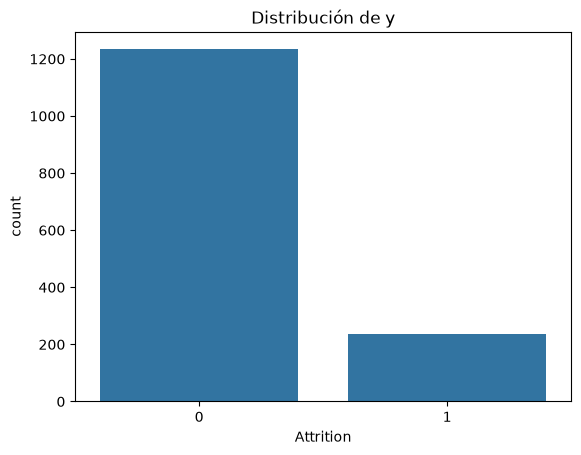

In [51]:
print(f"Tasa de deserción: {y.mean():.2%}")

sns.countplot(x=y)
plt.xticks([0, 1])
plt.title("Distribución de y")
plt.show()

Solo alrededor del 16% de los empleados se va, es decir, tenemos que la variable objetivo está desbalanceada. Esto es importante porque un modelo que siempre prediga "se queda" ya acertaría cerca del 84 %, así que la exactitud (accuracy) por sí sola engaña y por ende no sería la métrica ideal. Por eso más adelante usaremos también recall, F1 y compararemos todos los modelos.


### Tipos de variables

Separamos las variables en tres grupos porque cada una se analiza de forma distinta:

- **Categóricas:** son las de texto.
- **Numéricas discretas:** tienen pocos valores distintos (niveles de satisfacción del 1 al 4, años, etc.).
- **Numéricas continuas:** tienen muchos valores distintos (edad, ingreso mensual, etc.).


In [52]:
# Variables categóricas (texto)
cat_cols = []
cat_cols.append("BusinessTravel") # frecuencia de viajes de trabajo
cat_cols.append("Department") # departamento
cat_cols.append("EducationField") # área de estudios
cat_cols.append("Gender")  # género
cat_cols.append("JobRole") # puesto
cat_cols.append("MaritalStatus") # estado civil
cat_cols.append("OverTime") # ¿ hace horas extra?

# Variables numéricas discretas (pocos valores distintos)
disc_cols = []
disc_cols.append("DistanceFromHome") # distancia a casa
disc_cols.append("Education") # nivel de estudios (1 a 5)
disc_cols.append("EnvironmentSatisfaction") # satisfacción con el ambiente (1 a 4)
disc_cols.append("JobInvolvement") # involucramiento en el trabajo (1 a 4)
disc_cols.append("JobLevel") # nivel del puesto (1 a 5)
disc_cols.append("JobSatisfaction") # satisfacción con el puesto (1 a 4)
disc_cols.append("NumCompaniesWorked") # empresas donde ha trabajado
disc_cols.append("PercentSalaryHike") # porcentaje de aumento de sueldo
disc_cols.append("PerformanceRating") # evaluación de desempeño
disc_cols.append("RelationshipSatisfaction")# satisfacción con las relaciones (1 a 4)
disc_cols.append("StockOptionLevel") # nivel de opciones de acciones (0 a 3)
disc_cols.append("TrainingTimesLastYear") # capacitaciones el año pasado
disc_cols.append("WorkLifeBalance") # balance vida-trabajo (1 a 4)
disc_cols.append("YearsInCurrentRole") # años en el puesto actual
disc_cols.append("YearsSinceLastPromotion") # años desde el último ascenso
disc_cols.append("YearsWithCurrManager") # años con el mismo jefe

# Variables numéricas continuas
cont_cols = []
cont_cols.append("Age") # edad
cont_cols.append("DailyRate") # tarifa diaria
cont_cols.append("HourlyRate") # tarifa por hora
cont_cols.append("MonthlyIncome") # ingreso mensual
cont_cols.append("MonthlyRate") # tarifa mensual
cont_cols.append("TotalWorkingYears") # años totales trabajados
cont_cols.append("YearsAtCompany") # años en la empresa

# Las numéricas son las discretas más las continuas
num_cols = disc_cols + cont_cols

# Comprobamos que no se nos quedó ninguna variable fuera
print(len(cat_cols) + len(num_cols), "variables clasificadas de", X.shape[1])

30 variables clasificadas de 30
